TASK 1 : Data Acquisition and EDA

A. Download the Heart Disease Dataset

In [38]:
import pandas as pd
df = pd.read_csv('heart.csv', header=None)


B. Assign Column Names

In [39]:
columns = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','target']
df.columns = columns

C. Handle Missing Values

In [40]:
df = df.replace('?', pd.NA)

D. Encode Categorical Features

In [41]:
print(df.columns)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


In [42]:
import pandas as pd
import numpy as np

# RESET everything by reloading the dataset fresh with header=None and explicit column names
columns = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','target']
df = pd.read_csv('heart.csv', header=None, names=columns)

# Convert NAType or '?' to NaN
df = df.replace('?', np.nan)

# Show columns again
print(df.columns)

# Encode thal safely
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['thal'] = le.fit_transform(df['thal'].astype(str))


Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


E. Perform EDA

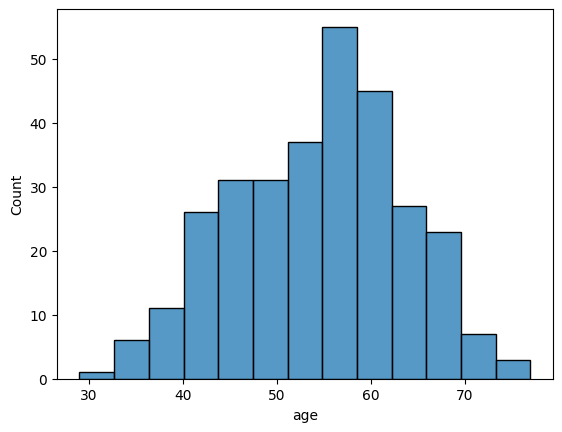

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(df['age']); plt.show()


F. Plot correlation Heatmap

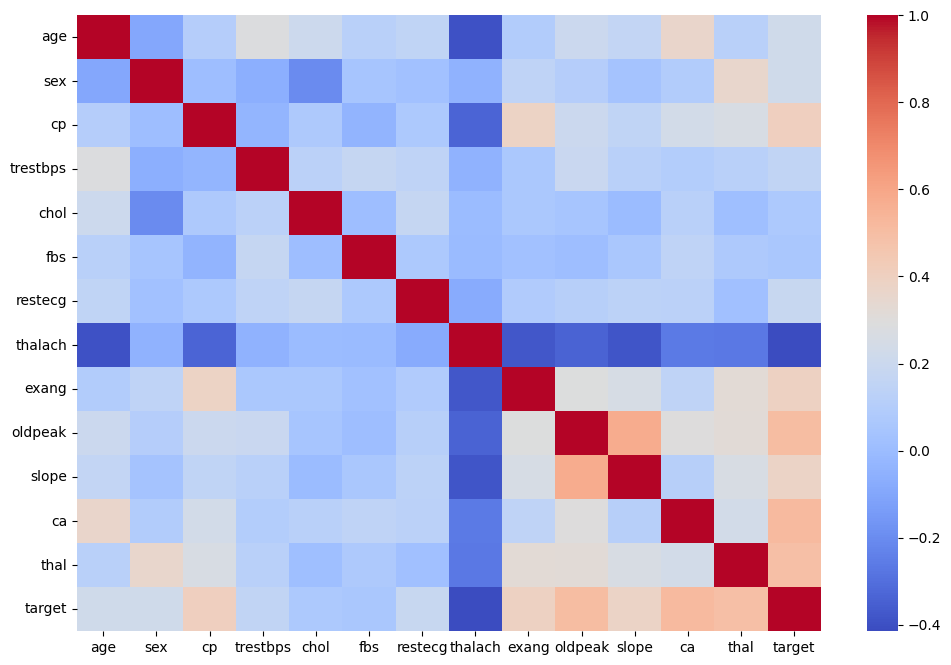

In [44]:
# Calculate the correlation matrix
corr = df.apply(pd.to_numeric, errors='coerce').corr()

# Plot the correlation heatmap
plt.figure(figsize=(12,8))
sns.heatmap(corr, annot=False, cmap='coolwarm')
plt.show()

G. Visualize Class Balance

Text(0.5, 1.0, 'Heart Disease Class Distribution')

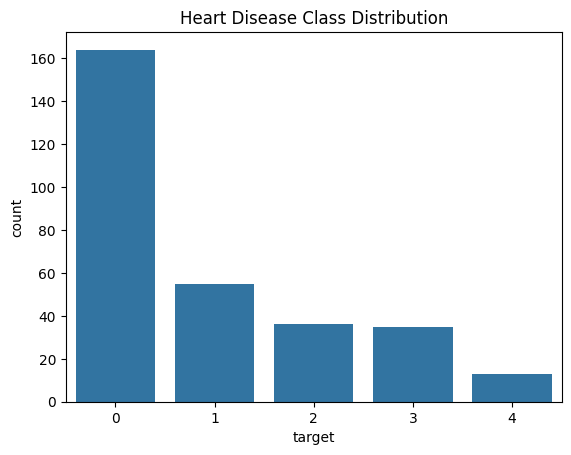

In [45]:
sns.countplot(x='target', data=df)
plt.title('Heart Disease Class Distribution')


H. Save Cleaned Dataset

In [46]:
df.to_csv('cleaned_heart.csv', index=False)


TASK 2 : Feature Engineering & Model Development

A. Identify feature types

In [47]:
# age, trestbps, chol, thalach, oldpeak
# sex, cp, fbs, restecg, exang, slope, ca, thal
# target (0 = no disease, 1 = disease)

B. Handle Missing Values

In [48]:
# @title
import pandas as pd
import numpy as np

df = pd.read_csv("heart.csv")
df = df.replace({pd.NA: np.nan})
df = df.dropna()   # or impute later


C. Train - Test Split

In [49]:
from sklearn.model_selection import train_test_split

# Ensure column names are set on the reloaded dataframe
columns = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','target']
if len(df.columns) == len(columns):
    df.columns = columns

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

D: Encoding + Scaling Pipeline

In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


In [51]:
numeric_features = ['age','trestbps','chol','thalach','oldpeak']
categorical_features = ['sex','cp','fbs','restecg','exang','slope','ca','thal']


In [52]:
preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)


E: Model 1 — Logistic Regression Pipeline

In [53]:
log_reg = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', LogisticRegression(max_iter=1000))
])


F: Model 2 — Random Forest Pipeline

In [54]:
rf = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', RandomForestClassifier(n_estimators=200, random_state=42))
])


G: Cross‑Validation Evaluation

In [55]:
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": log_reg,
    "Random Forest": rf
}

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    print(name, "Accuracy:", scores.mean())


Logistic Regression Accuracy: 0.5990710382513662
Random Forest Accuracy: 0.6090163934426229


H: Train Final Models

In [56]:
log_reg.fit(X_train, y_train)
rf.fit(X_train, y_train)


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal'])])),
                ('model',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

I: Model Evaluation (Accuracy, Precision, Recall, ROC‑AUC)

In [57]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

def evaluate(model, X_test, y_test):
    y_pred = model.predict(X_test)
    # For multiclass, predict_proba returns probabilities for all classes
    y_prob = model.predict_proba(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision (Weighted):", precision_score(y_test, y_pred, average='weighted'))
    print("Recall (Weighted):", recall_score(y_test, y_pred, average='weighted'))
    print("ROC-AUC (OVR, Weighted):", roc_auc_score(y_test, y_prob, multi_class='ovr', average='weighted'))

print("Logistic Regression:")
evaluate(log_reg, X_test, y_test)

print("\nRandom Forest:")
evaluate(rf, X_test, y_test)

Logistic Regression:
Accuracy: 0.6229508196721312
Precision (Weighted): 0.5276166456494326
Recall (Weighted): 0.6229508196721312
ROC-AUC (OVR, Weighted): 0.8702698741703829

Random Forest:
Accuracy: 0.5573770491803278
Precision (Weighted): 0.4466042154566745
Recall (Weighted): 0.5573770491803278
ROC-AUC (OVR, Weighted): 0.8481529486362726


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


J: Model Selection and Tuning

In [58]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10],
    'model__min_samples_split': [2, 5, 10]
}

grid = GridSearchCV(rf, param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print("Best Params:", grid.best_params_)
print("Best Score:", grid.best_score_)


Best Params: {'model__max_depth': 5, 'model__min_samples_split': 10, 'model__n_estimators': 100}
Best Score: 0.6141156462585033


TASK 3: Experiment Tracking

A: Install & Initialize MLflow

In [ ]:
!pip install mlflow

In [ ]:
!mkdir -p mlruns

B: Start MLflow Tracking Server

In [ ]:
# Start the MLflow UI in the background so it doesn't block notebook execution
import subprocess
import time

print("Starting MLflow UI server in background...")
subprocess.Popen(["mlflow", "ui", "--port", "5000", "--host", "0.0.0.0"])

# Give the server a couple of seconds to spin up
time.sleep(5)
print("MLflow UI is now running in the background.")

c: Add MLflow to THE Model Training Code

In [ ]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

def train_with_mlflow(model, model_name, X_train, X_test, y_train, y_test):
    with mlflow.start_run(run_name=model_name):

        # Train model
        model.fit(X_train, y_train)

        # Predictions
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:,1]

        # Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        auc = roc_auc_score(y_test, y_prob)

        # Log parameters (model hyperparameters)
        mlflow.log_params(model.get_params())

        # Log metrics
        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("precision", prec)
        mlflow.log_metric("recall", rec)
        mlflow.log_metric("roc_auc", auc)

        # Log model artifact
        mlflow.sklearn.log_model(model, model_name)

        print(f"Logged {model_name}:")
        print("Accuracy:", acc)
        print("Precision:", prec)
        print("Recall:", rec)
        print("ROC-AUC:", auc)


D:  Confusion Matrix

In [59]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

def log_confusion_matrix(model, X_test, y_test, model_name):
    disp = ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)
    plt.title(f"{model_name} Confusion Matrix")
    plt.savefig(f"{model_name}_cm.png")
    mlflow.log_artifact(f"{model_name}_cm.png")


🏃 View run Logistic Regression CM at: http://127.0.0.1:5000/#/experiments/1/runs/eb286fa4b442496b98abb086a3670790
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run Random Forest CM at: http://127.0.0.1:5000/#/experiments/1/runs/2a3b7e9fa3ec464c985a15b8da92009a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


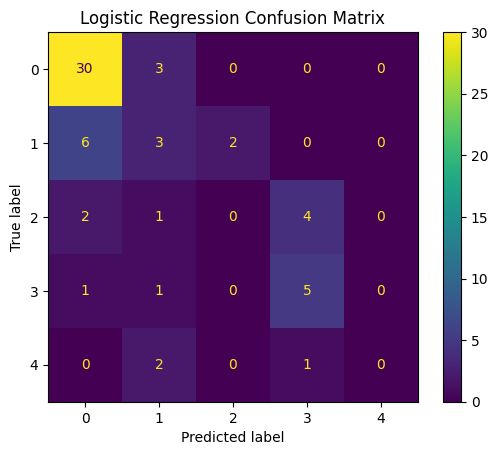

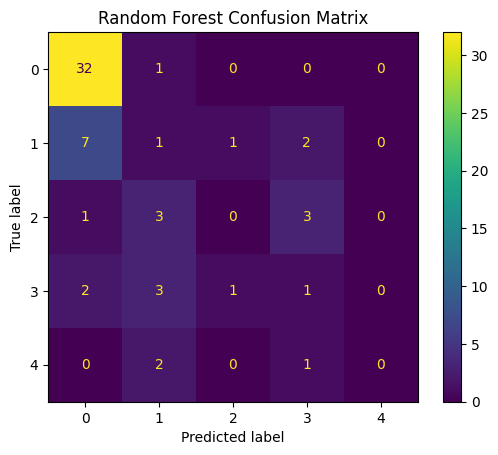

In [60]:
import mlflow

# Safely close any previously active or dangling MLflow runs in this session
if mlflow.active_run() is not None:
    mlflow.end_run()

# Configure MLflow to point to the local HTTP tracking server
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Log confusion matrices inside a specific or active run context
# (Using set_experiment to organize them)
mlflow.set_experiment("Heart_Disease_Evaluation")

# We start a run for Logistic Regression and log its artifact
with mlflow.start_run(run_name="Logistic Regression CM"):
    log_confusion_matrix(log_reg, X_test, y_test, "Logistic Regression")

# We start a run for Random Forest and log its artifact
with mlflow.start_run(run_name="Random Forest CM"):
    log_confusion_matrix(rf, X_test, y_test, "Random Forest")

Task 4: Model Packaging & Reproducibility

In [61]:
import pandas as pd
import numpy as np
import pickle

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


In [62]:
df = pd.read_csv("cleaned_heart.csv")

target_col = "target"
X = df.drop(target_col, axis=1)
y = df[target_col]


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [64]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])


In [65]:
pipeline.fit(X_train, y_train)
print("Model trained successfully!")


Model trained successfully!


In [66]:
with open("final_model.pkl", "wb") as f:
    pickle.dump(pipeline, f)

print("Model saved as final_model.pkl")


Model saved as final_model.pkl


In [67]:
metadata = {
    "feature_names": list(X.columns),
    "target_name": target_col
}

with open("metadata.pkl", "wb") as f:
    pickle.dump(metadata, f)

print("Metadata saved as metadata.pkl")


Metadata saved as metadata.pkl


In [68]:
import pkg_resources

packages = [pkg.key + "==" + pkg.version for pkg in pkg_resources.working_set]

with open("requirements.txt", "w") as f:
    f.write("\n".join(packages))

print("requirements.txt created")


requirements.txt created


In [69]:
with open("final_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)

print("Sample prediction:", loaded_model.predict(X_test.iloc[0:1]))


Sample prediction: [2]


TASK 5: CI/CD Pipeline & Automated Testing